# ⚡ PowerCast — Demo Notebook
Forecast a household's electricity use for the next 24 hours using a Seasonal Naive model (tomorrow = yesterday).

## 0. Setup (Google Colab only)

In [7]:
# Run this cell only on Google Colab
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/PowerCast

ModuleNotFoundError: No module named 'google.colab'

## 1. Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from predict import predict_next_24h

## 2. Load the data

In [2]:
df = pd.read_csv("data/hourly_clean.csv", parse_dates=["datetime"])
series = df.set_index("datetime")["Global_active_power"]
test = df[df["split"] == "test"]

print("Rows:", len(df))
print("Test from", test["datetime"].min(), "to", test["datetime"].max())

Rows: 34589
Test from 2010-07-01 00:00:00 to 2010-11-26 21:00:00


## 3. Forecast one day

In [3]:
day = pd.Timestamp("2010-08-17")

history = series[day - pd.Timedelta(hours=168) : day - pd.Timedelta(hours=1)]
actual = series[day : day + pd.Timedelta(hours=23)]
forecast = predict_next_24h(history.values)

print("History hours:", len(history))
print("Actual hours:", len(actual))
print("Forecast:", forecast.round(2))

History hours: 168
Actual hours: 24
Forecast: [0.35 1.25 0.29 0.26 0.29 0.31 0.28 0.33 0.26 0.34 0.26 0.27 0.44 1.15
 0.29 0.3  0.32 0.28 0.32 0.26 0.3  0.28 0.33 0.28]


## 4. Actual vs Forecast chart

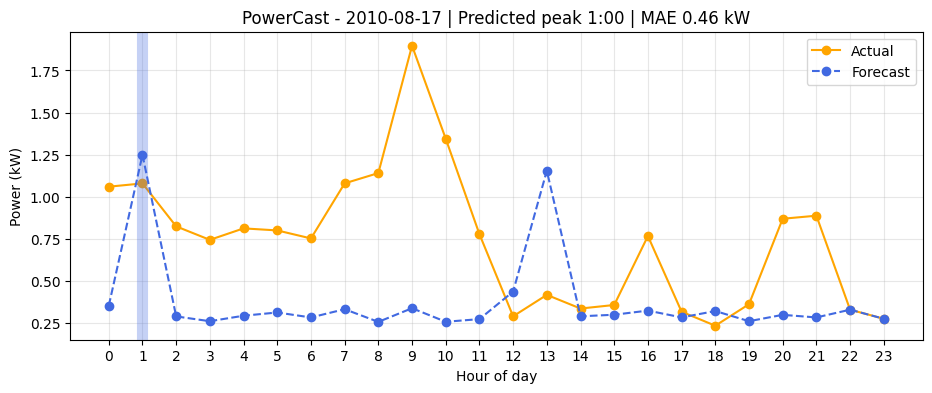

In [4]:
hours = range(24)
peak = forecast.argmax()
mae = abs(actual.values - forecast).mean()

plt.figure(figsize=(11, 4))
plt.plot(hours, actual.values, color="orange", marker="o", label="Actual")
plt.plot(hours, forecast, color="royalblue", marker="o", linestyle="--", label="Forecast")
plt.axvline(peak, color="royalblue", alpha=0.3, linewidth=8)

plt.title(f"PowerCast - {day.date()} | Predicted peak {peak}:00 | MAE {mae:.2f} kW")
plt.xlabel("Hour of day")
plt.ylabel("Power (kW)")
plt.xticks(hours)
plt.grid(alpha=0.3)
plt.legend()
plt.savefig(f"figures/demo_{day.date()}.png", dpi=150)
plt.show()

## 5. Backup images for the presentation

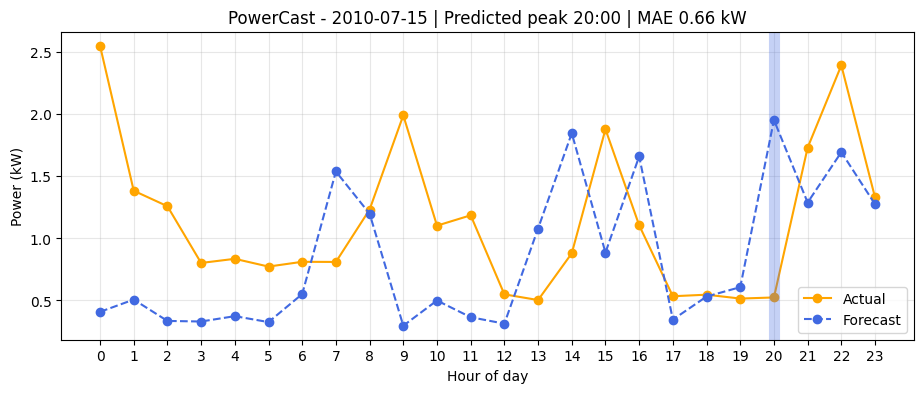

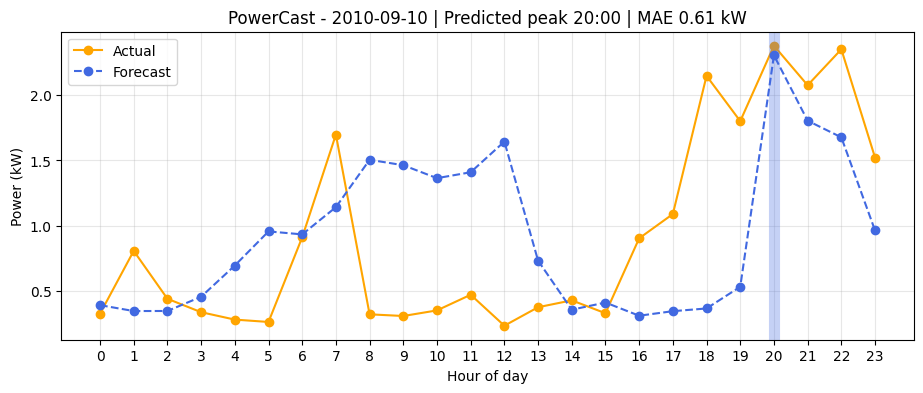

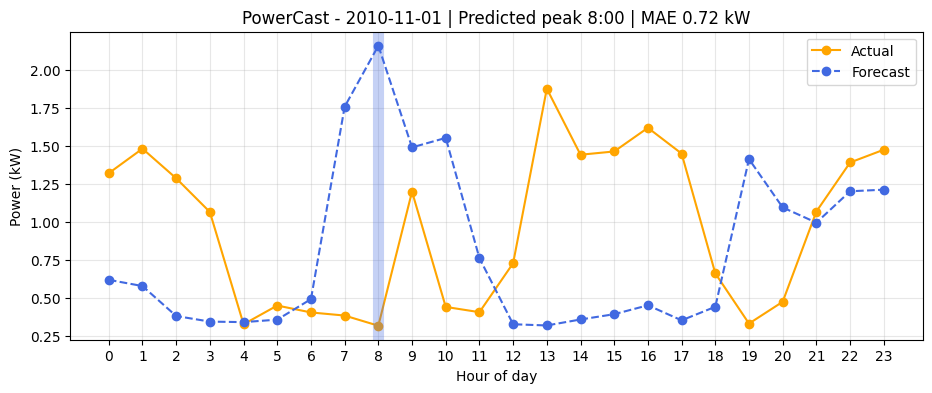

In [5]:
def plot_day(day_text):
    day = pd.Timestamp(day_text)
    history = series[day - pd.Timedelta(hours=168) : day - pd.Timedelta(hours=1)]
    actual = series[day : day + pd.Timedelta(hours=23)]
    forecast = predict_next_24h(history.values)
    peak = forecast.argmax()
    mae = abs(actual.values - forecast).mean()

    plt.figure(figsize=(11, 4))
    plt.plot(range(24), actual.values, color="orange", marker="o", label="Actual")
    plt.plot(range(24), forecast, color="royalblue", marker="o", linestyle="--", label="Forecast")
    plt.axvline(peak, color="royalblue", alpha=0.3, linewidth=8)
    plt.title(f"PowerCast - {day.date()} | Predicted peak {peak}:00 | MAE {mae:.2f} kW")
    plt.xlabel("Hour of day")
    plt.ylabel("Power (kW)")
    plt.xticks(range(24))
    plt.grid(alpha=0.3)
    plt.legend()
    plt.savefig(f"figures/demo_{day.date()}.png", dpi=150)
    plt.show()

for d in ["2010-07-15", "2010-09-10", "2010-11-01"]:
    plot_day(d)

## 6. Overall result on the test period

In [6]:
days = pd.date_range("2010-07-01", "2010-11-25")
errors = []
for d in days:
    history = series[d - pd.Timedelta(hours=168) : d - pd.Timedelta(hours=1)]
    actual = series[d : d + pd.Timedelta(hours=23)]
    forecast = predict_next_24h(history.values)
    errors.append(abs(actual.values - forecast).mean())

print("Test days:", len(errors))
print("Average daily MAE:", round(sum(errors) / len(errors), 2), "kW")

Test days: 148
Average daily MAE: 0.52 kW
